# Assignment 2: Rainfall and Water in the Atmosphere

*Notebook made by: Markus Jehl (s243647), Maja Søholm Eskelund (s235129), Malthe Tretow-Loof (s242273), Sarah Badstue Ringgaard Sørensen (s244739) & Victor Sejthen (s235137)*

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import numpy as np
from scipy import stats 
from IPython.display import Image, display
import sympy as sp

## Part A: Precipitation measurements

### A.1

The code imports the data for Botanisk Have from the series 5735_601 over the time period 1990-2010. The plot shows the precipitation for Botanisk Have in mm/day over the period.

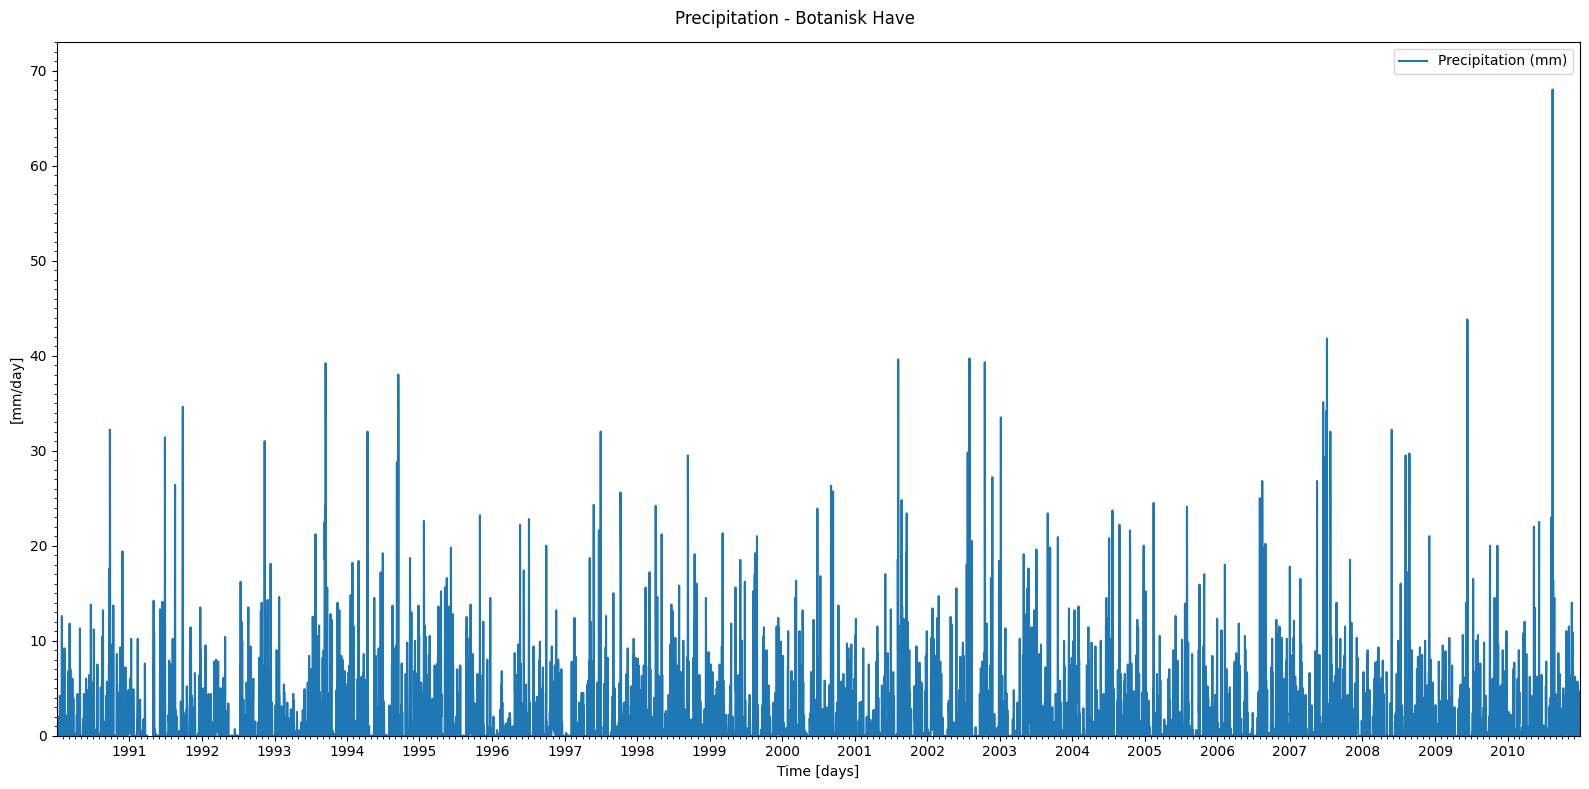

In [2]:
#reading datfile with space delimiter and converting "null" to NA values. 
df_bh = pd.read_csv(r"Assignment2_PartA_data/dk_daily_5735_601.csv",delimiter=" ",na_values=["null"])

df_bh_sub = df_bh[(df_bh["year"] >= 1990) & (df_bh["year"] <= 2010)]

#formatting of dates to datetime
df_bh_sub['dateInt'] = df_bh_sub['year'].astype(str)+df_bh_sub['month'].astype(str).str.zfill(2)+df_bh_sub['day'].astype(str).str.zfill(2)+df_bh_sub['hour'].astype(str).str.zfill(2)
df_bh_sub['date']=pd.to_datetime(df_bh_sub['dateInt'],format='%Y%m%d%H')


#plotting of data
fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(df_bh_sub['date'], df_bh_sub['elem_val'], label="Precipitation (mm)")
ax.set_ylabel('[mm/day]')
ax.set_xlabel('Time [days]')
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.yaxis.set_major_locator(ticker.MultipleLocator(10)) # store ticks 
ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.legend()
ax.set_xlim(df_bh_sub['date'].min(), df_bh_sub['date'].max())
ax.set_ylim(df_bh_sub['elem_val'].min(),df_bh_sub['elem_val'].max()+5)
fig.suptitle('Precipitation - Botanisk Have')
fig.tight_layout()
plt.show()

### A.2

The code imports the data from the grid cells 10566 and 10580 in the same time period (1990-2010) as above. The plot shows the precipitation for the grid cells in mm/day over the period. The plot illustrates a high degree of spatial correlation between the two grid cells, as their precipitation spikes align closely across the twenty-year period.

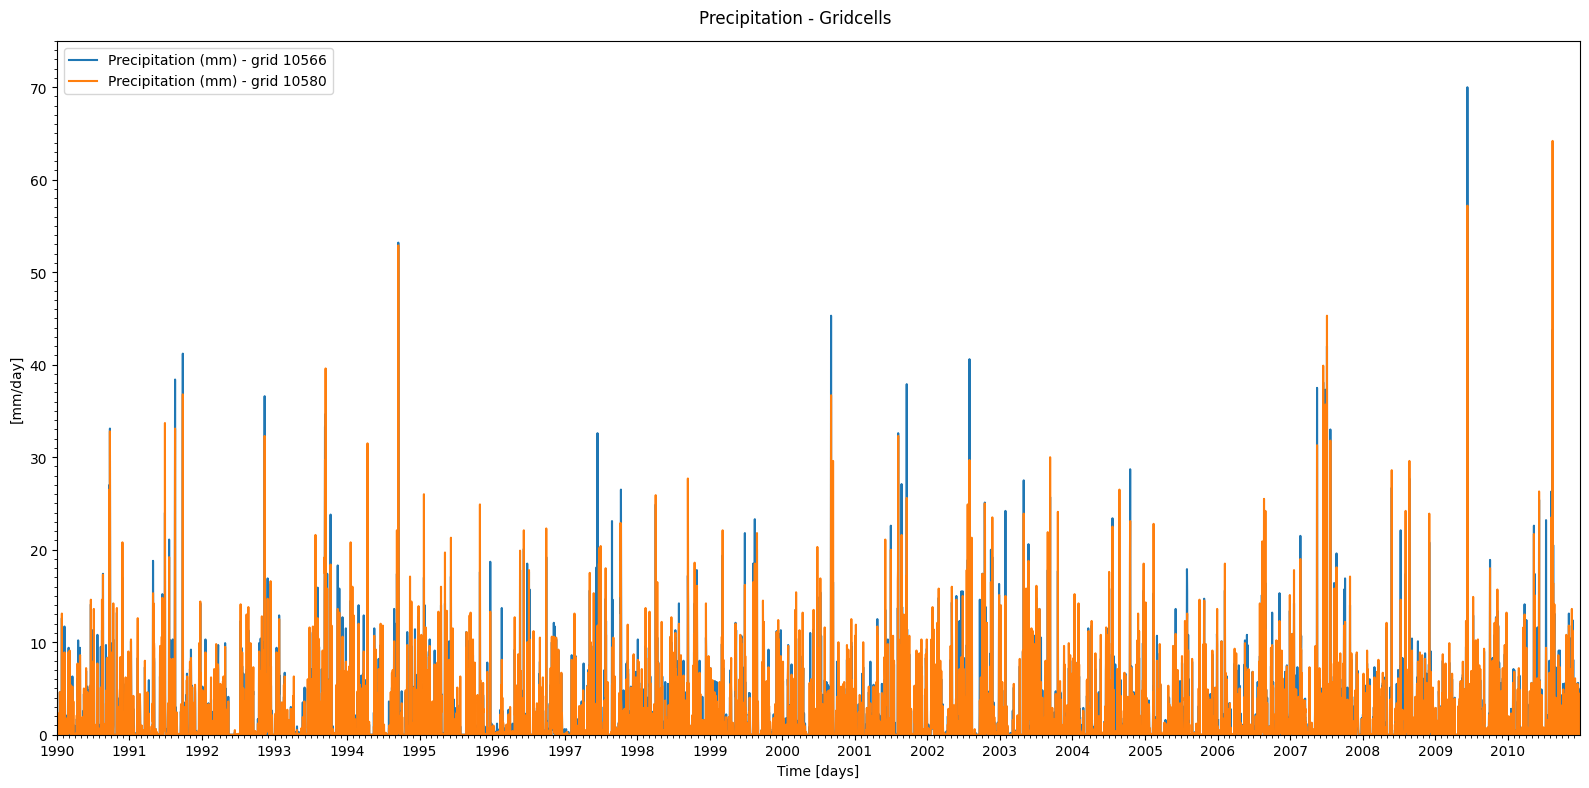

In [3]:
data_path = r"Assignment2_PartA_data/daily_10x10km_precipitation_1989-2010.txt"
#Open the text file, read line by line and the convert into a dataframe

fp = open(data_path,'r')
header=next(fp).split(';')
griddata=[line.split(';') for line in fp if line.split(';')[3] in ['10566','10580']]
del fp
# create a datafram and convert the different collumns from string to numeric
griddf = pd.DataFrame(griddata,columns=header)
griddf['year'] = pd.to_numeric(griddf['year'])
griddf['month'] = pd.to_numeric(griddf['month'])
griddf['day'] = pd.to_numeric(griddf['day'])
griddf['gridcelle'] = pd.to_numeric(griddf['gridcelle'])
griddf['eastings'] = pd.to_numeric(griddf['eastings'])
griddf['northings'] = pd.to_numeric(griddf['northings'])
griddf['10*10km_Observed_precipitation_(mm)'] = pd.to_numeric(griddf['10*10km_Observed_precipitation_(mm)'])

#add a column with a datetime, that python can intepret
griddf['dateInt'] = griddf['year'].astype(str)+griddf['month'].astype(str).str.zfill(2)+griddf['day'].astype(str).str.zfill(2)
griddf['date']=pd.to_datetime(griddf['dateInt'],format='%Y%m%d')


#create subsets, only containing one gridcell in each set:
griddf_10566 = griddf[(griddf['gridcelle'] == 10566) & (griddf["year"] >= 1990) & (griddf["year"] <= 2010)]
griddf_10580 = griddf[(griddf['gridcelle'] == 10580) & (griddf["year"] >= 1990) & (griddf["year"] <= 2010)]

#plot data
fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(griddf_10566['date'], griddf_10566['10*10km_Observed_precipitation_(mm)'], label="Precipitation (mm) - grid 10566")
ax.plot(griddf_10580['date'], griddf_10580['10*10km_Observed_precipitation_(mm)'], label="Precipitation (mm) - grid 10580")
ax.set_ylabel('[mm/day]')
ax.set_xlabel('Time [days]')
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.yaxis.set_major_locator(ticker.MultipleLocator(10)) # store ticks 
ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.legend()
ax.set_xlim(griddf_10566['date'].min(), griddf_10566['date'].max())
ax.set_ylim(griddf_10580['10*10km_Observed_precipitation_(mm)'].min(),max(griddf_10566['10*10km_Observed_precipitation_(mm)'].max(),griddf_10580['10*10km_Observed_precipitation_(mm)'].max())+5)
fig.suptitle('Precipitation - Gridcells')
fig.tight_layout()
plt.show()

In [4]:
display(griddf)

,year,month,day,gridcelle,utm_zone,eastings,northings,10*10km_Observed_precipitation_(mm),releasedato\n,dateInt,date
0,1989,1,2,10566,32V,705000,6165000,0.0,19990813\n,19890102,1989-01-02
1,1989,1,2,10580,32V,715000,6175000,0.0,19990813\n,19890102,1989-01-02
2,1989,1,3,10566,32V,705000,6165000,0.0,19990813\n,19890103,1989-01-03
3,1989,1,3,10580,32V,715000,6175000,0.0,19990813\n,19890103,1989-01-03
4,1989,1,4,10566,32V,705000,6165000,0.0,19990813\n,19890104,1989-01-04
...,...,...,...,...,...,...,...,...,...,...,...
16065,2010,12,30,10580,32V,715000,6175000,0.0,20110120\n,20101230,2010-12-30
16066,2010,12,31,10566,32V,705000,6165000,0.7,20110120\n,20101231,2010-12-31
16067,2010,12,31,10580,32V,715000,6175000,1.2,20110120\n,20101231,2010-12-31
16068,2011,1,1,10566,32V,705000,6165000,0.3,20110120\n,20110101,2011-01-01


### A.3

Using a GIS program the grid cells 10566 and 10580 are determined to be 9.646 km from Botanisk Have.

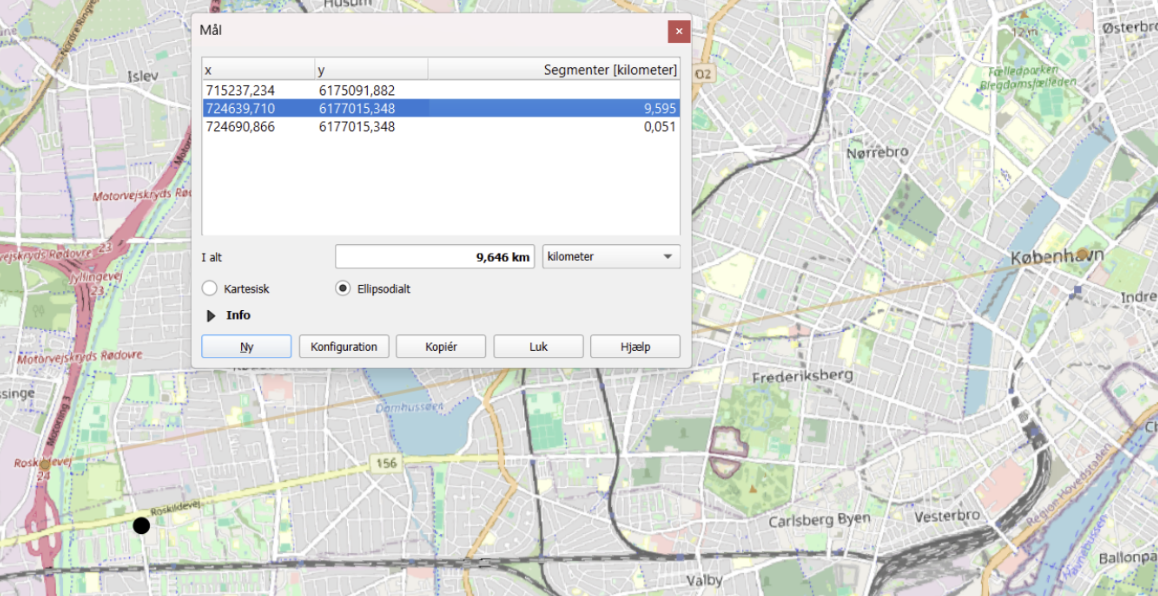

In [5]:
display(Image("Assignment2_PartA_data/GIS.png"))

### A.4

Plotting the time series of precipitation for the two grid cells and the station data for August 2002, shows the mm/day over the month. Due to the dataset recording percipitation per day and not hour and over a 10 x 10 km area, pinpointing the date where the tipping bucket gauge in grid 10566 recorded 102 mm rainfall within 3 hours is estimated with great uncertainty. Since extreme rainfall is often highly localized, a single gauge may record much higher totals than the average of the entire grid cell. However, based on the daily records the 102 mm event most likely occurred on a day with high observed totals, such as August 1st or 3rd. An argument for the 3rd could be made, that Grid 10566 got a lot of precipitation, while the grids closeby, here 10580 and Botanisk Have, got much less.

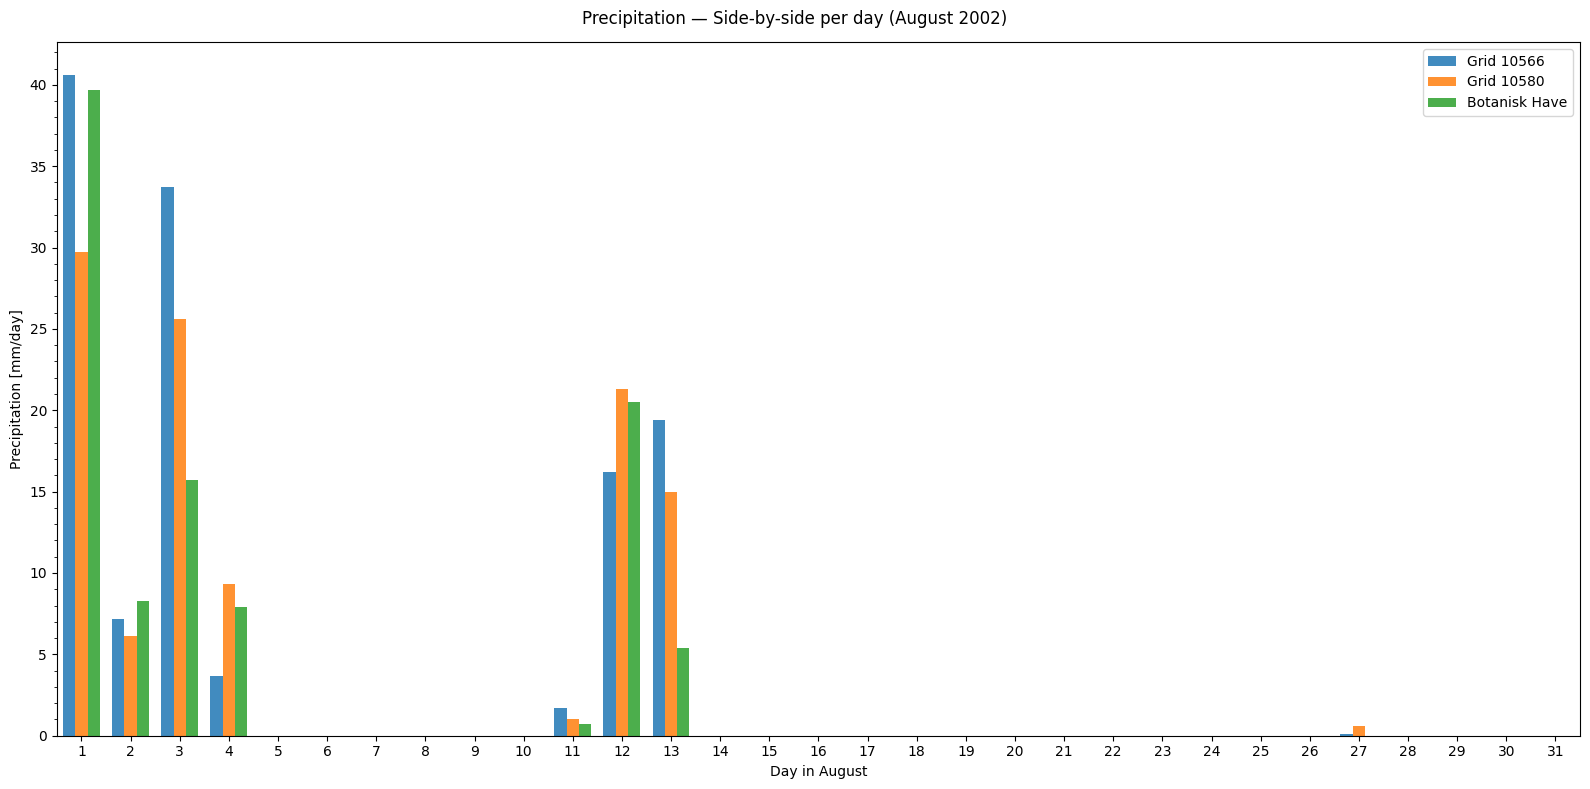

In [6]:
#calling in dataframes for the specific stations
df_10566_2002_8 = griddf[(griddf['gridcelle']==10566)&(griddf['year'] == 2002) & (griddf['month'] == 8)]
df_10580_2002_8 = griddf[(griddf['gridcelle']==10580)&(griddf['year'] == 2002) & (griddf['month'] == 8)]
df_bh_2002_8 = df_bh_sub[(df_bh_sub['year'] == 2002) & (df_bh_sub['month'] == 8)]

# 1) Make sure that Day is an integer
for d in (df_10566_2002_8, df_10580_2002_8, df_bh_2002_8):
    d['day'] = pd.to_numeric(d['day'], errors='coerce').astype('Int64')

# 2) Make a complete day axis (1..31)
days = pd.Series(np.arange(1, 32), name='day')
df_plot = pd.DataFrame({'day': days})

# 3) Merge values into the day axis
df_plot = (df_plot.merge(df_10566_2002_8[['day', '10*10km_Observed_precipitation_(mm)']],
           on='day', how='left').merge(df_10580_2002_8[['day', '10*10km_Observed_precipitation_(mm)']],
           on='day', how='left', suffixes=('_10566', '_10580')).merge(df_bh_2002_8[['day', 'elem_val']], on='day', how='left'))

# 4) Define x-positions and bar width
x = df_plot['day'].to_numpy()         # 1..31
width = 0.25                          # Bar width
offset = width                        # Offset between groups

# 5) Plot side-by-side
fig, ax = plt.subplots(figsize=(16, 8))

ax.bar(x - offset, df_plot['10*10km_Observed_precipitation_(mm)_10566'],
       width=width, label='Grid 10566', alpha=0.85)
ax.bar(x,          df_plot['10*10km_Observed_precipitation_(mm)_10580'],
       width=width, label='Grid 10580', alpha=0.85)
ax.bar(x + offset, df_plot['elem_val'],
       width=width, label='Botanisk Have', alpha=0.85)

# 6) Axes, ticks and labels
ax.set_xlabel('Day in August')
ax.set_ylabel('Precipitation [mm/day]')
ax.set_xlim(0.5, 31.5)                         # Side margins
ax.set_xticks(np.arange(1, 32, 1))             # 1..31
ax.legend()
ax.yaxis.set_major_locator(ticker.MultipleLocator(5)) 
ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))
fig.suptitle('Precipitation — Side-by-side per day (August 2002)')
fig.tight_layout()
plt.show()

### A.5

A double-mass curve is used to evaluate the consistency between two precipitation datasets by comparing their cumulative values. If the datasets are consistent, the data points will follow a straight line. The slope of this line indicates the proportional relationship between the datasets, while deviations from the 1:1 line indicate differences in precipitation at the locations.

**BH vs Gridcell 10566**
The data show an approximately linear relationship, indicating consistency over time. The slope is lower than the 1:1 line, which suggests that cumulative precipitation in Gridcell 10566 is generally lower than in BH.

**BH vs Gridcell 10580**
A linear relationship is also observed, suggesting consistent behaviour over time. The slope is closer to the 1:1 line than for Gridcell 10566, but still slightly lower, indicating that Gridcell 10580 also underestimates precipitation relative to BH.

**Gridcell 10566 vs Gridcell 10580**
The relationship between the two grid cells is approximately parallel, indicating similar temporal behaviour and accumulation rates. The slight offset from the 1:1 line suggests a minor systematic difference between the two grid cells.


The double-mass curves indicates that BH has higher cumulative precipitation than both grid cells, as both relationships have slopes lower than the 1:1 line. In contrast, the two grid cells exhibit very similar behaviour, with nearly identical accumulation rates and only a small systematic difference between them.

In [7]:
#cumulative sum of precipitation for both grids, and Botanisk Have
cum_precip_10566 = df_10566_2002_8['10*10km_Observed_precipitation_(mm)'].cumsum()
cum_precip_10580 = df_10580_2002_8['10*10km_Observed_precipitation_(mm)'].cumsum()
cum_precip_bh = df_bh_2002_8['elem_val'].cumsum()


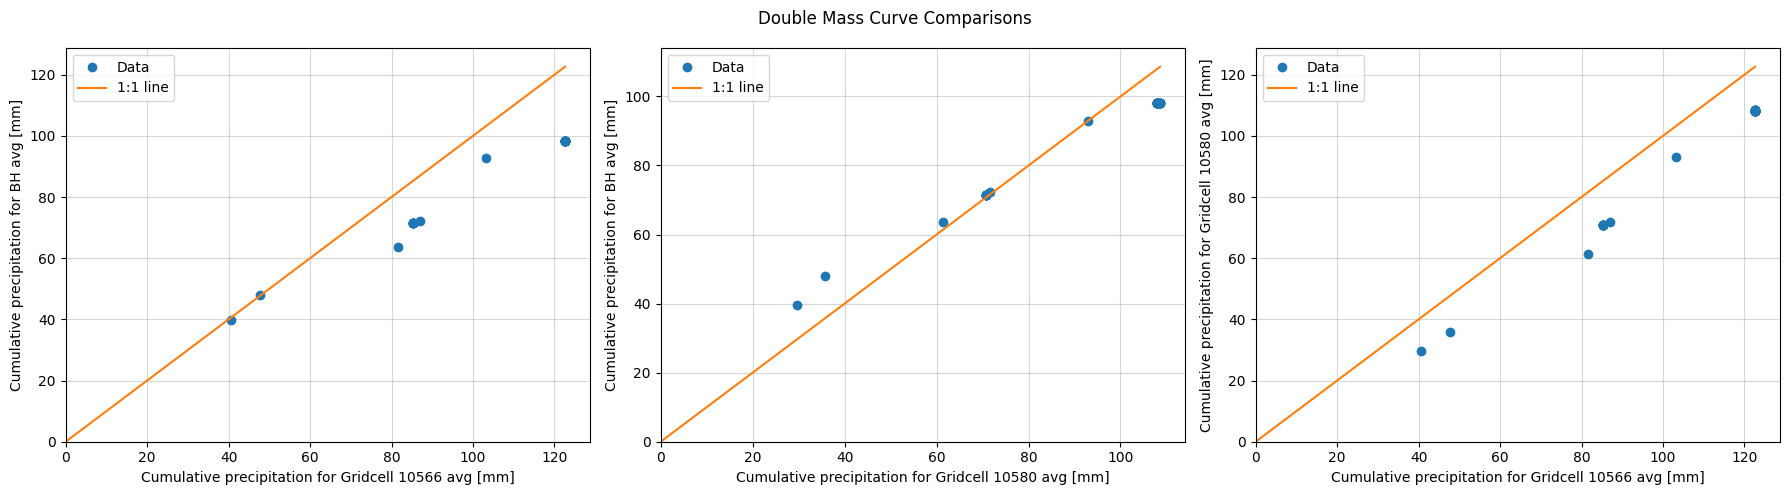

In [8]:
def double_mass_curve(ax, x, y, xlabel, ylabel):

    max_val = max(x.max(), y.max())

    ax.plot(x, y, 'o', label='Data')
    ax.plot([0, max_val], [0, max_val], label='1:1 line')
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    ax.set_xlabel(f"Cumulative precipitation for {xlabel} avg [mm]")
    ax.set_ylabel(f"Cumulative precipitation for {ylabel} avg [mm]")
    fig.suptitle(f"Double Mass Curve Comparisons")
    ax.legend()
    ax.grid(alpha=0.5)

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

double_mass_curve(
    axes[0],
    cum_precip_10566,
    cum_precip_bh,
    'Gridcell 10566',
    'BH'
)

double_mass_curve(
    axes[1],
    cum_precip_10580,
    cum_precip_bh,
    'Gridcell 10580',
    'BH'
)

double_mass_curve(
    axes[2],
    cum_precip_10566,
    cum_precip_10580,
    'Gridcell 10566',
    'Gridcell 10580'
)

plt.tight_layout()
plt.show()

### A.6

The correlation between the three precipitation series was evaluated at daily, monthly, and annual time scales.

At the daily scale, the correlations are relatively high, ranging from 0.88 to 0.95. The highest correlation is observed between BH and Gridcell 10580 (0.95), while the lowest is between BH and Gridcell 10566 (0.88). This indicates that Gridcell 10580 better represents the daily variability observed at BH.

At the monthly scale, the correlations increase for all series (0.94–0.98). This reflects the effect of temporal aggregation, where short-term variability is smoothed out, leading to stronger agreement between the datasets.

At the annual scale, the correlations remain high (0.88–0.96), although slightly lower than for the monthly scale. This may be due to the limited number of data points at this scale, making the correlation more sensitive to individual years.

Overall, Gridcell 10580 shows consistently higher correlation with BH than Gridcell 10566 across all time scales, suggesting that it better captures the precipitation patterns observed at the station. This makes sence because the tipping gauge in Botanisk Have is closer to Gridcell 1580. The two grid cells are also highly correlated with each other, indicating strong internal consistency in the gridded dataset.

In [9]:
#define a common expression for years between excluded years between 1990 and 2010
griddf_sub = griddf[(griddf["year"] >= 1990) & (griddf["year"] <= 2010)]

#define function for correlations between gridcells and Botanisk Have by day, month and year
def correlation_three_series(df_bh_sub, griddf_sub, timescale, tekst):

    if timescale == 'day':
        keys = ['year', 'month', 'day']
    elif timescale == 'month':
        keys = ['year', 'month']
    else:
        timescale == 'year'
        keys = ['year']

    BH = (
        df_bh_sub
        .groupby(keys)['elem_val']
        .sum()
        .reset_index()
        .rename(columns={'elem_val': 'BH'})
    )

    grid10566 = (
        griddf_sub.loc[griddf_sub['gridcelle'] == 10566]
        .groupby(keys)['10*10km_Observed_precipitation_(mm)']
        .sum()
        .reset_index()
        .rename(columns={'10*10km_Observed_precipitation_(mm)': '10566'})
    )

    grid10580 = (
        griddf_sub.loc[griddf_sub['gridcelle'] == 10580]
        .groupby(keys)['10*10km_Observed_precipitation_(mm)']
        .sum()
        .reset_index()
        .rename(columns={'10*10km_Observed_precipitation_(mm)': '10580'})
    )

    merged = (
    BH.merge(grid10566, on=keys)
    .merge(grid10580, on=keys))

    corr = merged[['BH', '10566', '10580']].corr()

    corr.columns = pd.MultiIndex.from_product(
    [[f"{tekst} correlation coefficients"], corr.columns])

    return corr



display(correlation_three_series(df_bh_sub, griddf_sub, 'day','Daily').round(2))
display(correlation_three_series(df_bh_sub, griddf, 'month', 'Monthly').round(2))
display(correlation_three_series(df_bh_sub, griddf, 'year','Yearly').round(2))

Daily correlation coefficients            
                                  BH 10566 10580
BH                              1.00  0.88  0.95
10566                           0.88  1.00  0.94
10580                           0.95  0.94  1.00

Monthly correlation coefficients            
                                    BH 10566 10580
BH                                1.00  0.94  0.98
10566                             0.94  1.00  0.97
10580                             0.98  0.97  1.00

Yearly correlation coefficients            
                                   BH 10566 10580
BH                               1.00  0.88  0.94
10566                            0.88  1.00  0.96
10580                            0.94  0.96  1.00

Below is scatter correlations plots for daily, monthly and yearly precipitation.

In [10]:
#plots the correlation as scatterplot
def scatter_correlation_plots(griddf_sub, df_bh_sub, timescale):

    if timescale == 'day':
        keys = ['year','month','day']
        title_scale = 'Daily'
    elif timescale == 'month':
        keys = ['year','month']
        title_scale = 'Monthly'
    elif timescale == 'year':
        keys = ['year']
        title_scale = 'Annual'

    # BH
    BH = (
        df_bh_sub
        .groupby(keys)['elem_val']
        .sum()
        .reset_index()
        .rename(columns={'elem_val': 'BH'})
    )

    # Gridcell 10566
    grid10566 = (
        griddf_sub.loc[griddf_sub['gridcelle'] == 10566]
        .groupby(keys)['10*10km_Observed_precipitation_(mm)']
        .sum()
        .reset_index()
        .rename(columns={'10*10km_Observed_precipitation_(mm)': '10566'})
    )

    # Gridcell 10580
    grid10580 = (
        griddf_sub.loc[griddf_sub['gridcelle'] == 10580]
        .groupby(keys)['10*10km_Observed_precipitation_(mm)']
        .sum()
        .reset_index()
        .rename(columns={'10*10km_Observed_precipitation_(mm)': '10580'})
    )

    # Merge datasets
    merged = (
        BH
        .merge(grid10566, on=keys)
        .merge(grid10580, on=keys)
    )

    # Create figure with 3 subplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    def plot_pair(ax, x, y, xlabel, ylabel):

        corr = merged[x].corr(merged[y])
        max_val = max(merged[x].max(), merged[y].max())

        ax.scatter(merged[x], merged[y], alpha=0.6)

        # 1:1 line
        ax.plot([0, max_val], [0, max_val], color='orange')

        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_title(f'{title_scale} (r = {corr:.3f})')
        ax.grid(alpha=0.5)

    # Plot on each axis
    plot_pair(axes[0], 'BH', '10566',
              'Grid 10566 precipitation [mm]',
              'BH precipitation [mm]')

    plot_pair(axes[1], 'BH', '10580',
              'Grid 10580 precipitation [mm]',
              'BH precipitation [mm]')

    plot_pair(axes[2], '10566', '10580',
              'Grid 10566 precipitation [mm]',
              'Grid 10580 precipitation [mm]')

    plt.tight_layout()
    plt.show()

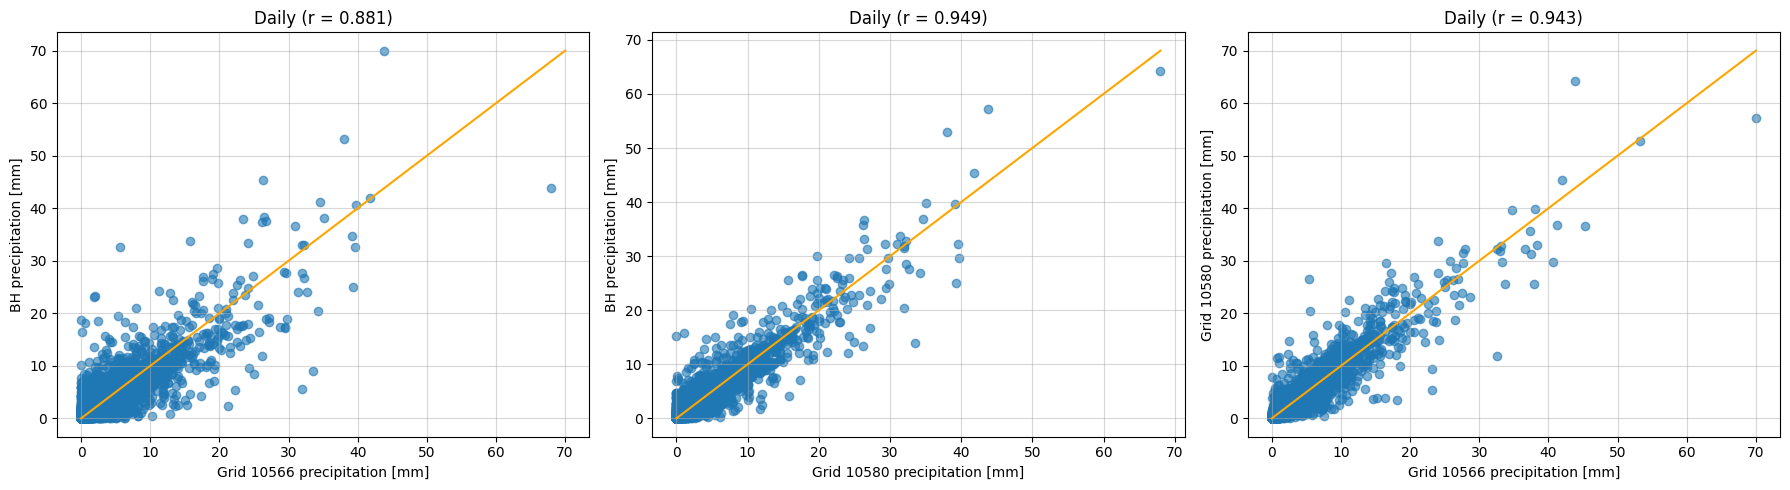

In [11]:
scatter_correlation_plots(griddf_sub, df_bh_sub, 'day') #daily

The daily scatter plots show a clear positive relationship between all three datasets, consistent with the calculated correlations.

The comparison between BH and Gridcell 10566 shows the largest spread around the 1:1 line and the lowest correlation (r = 0.881). This indicates greater variability and weaker agreement on a daily basis.

For BH and Gridcell 10580, the points are more tightly clustered around the 1:1 line, reflecting a higher correlation (r = 0.949). This suggests that Gridcell 10580 better captures the daily variability observed at BH.

The comparison between Gridcell 10566 and Gridcell 10580 also shows a strong linear relationship (r = 0.943), with relatively limited scatter. This indicates that the two grid cells are highly consistent with each other at the daily scale.

Overall, the scatter increases with rainfall magnitude, and there is a noticeable spread at higher values. This reflects the influence of local variability and the difference between point measurements (BH) and spatially averaged grid data, which tends to smooth extreme events.

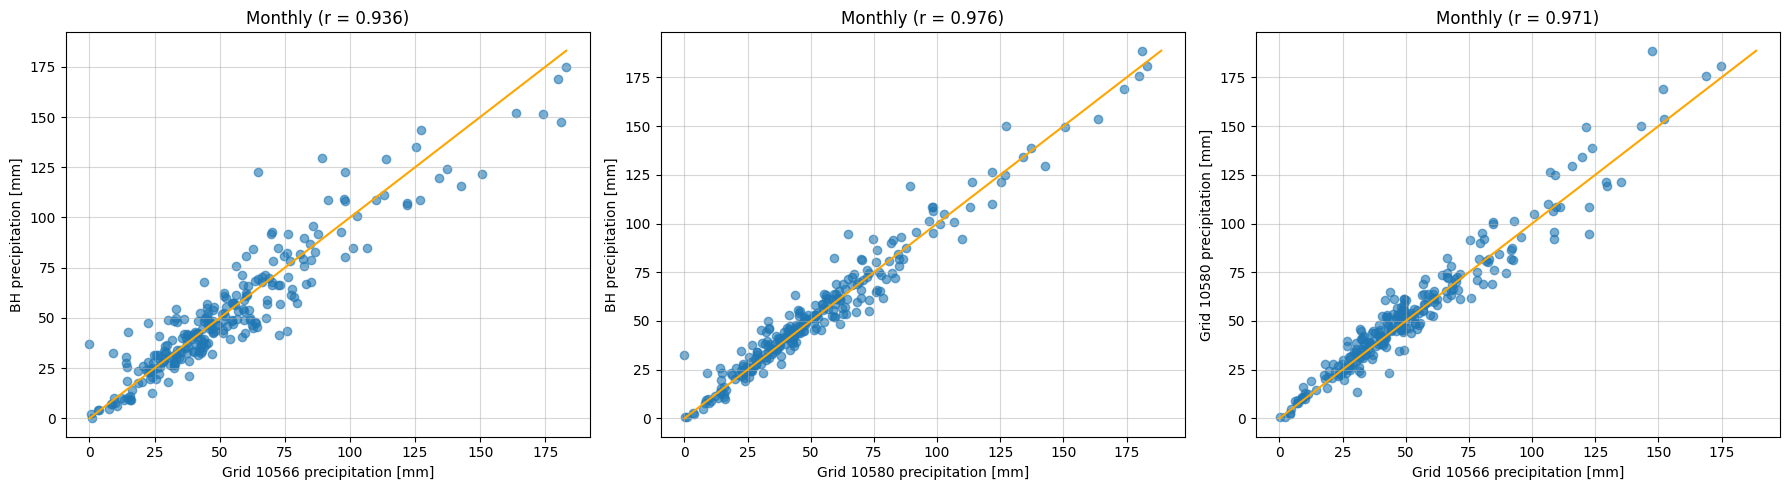

In [12]:
scatter_correlation_plots(griddf_sub, df_bh_sub, 'month') #monthly

The monthly scatter plots show a stronger linear relationship between the datasets compared to the daily scale, consistent with the higher correlation coefficients.

For BH and Gridcell 10566 (r = 0.936), the points are more tightly clustered around the 1:1 line than in the daily case, although some spread is still present. This indicates improved agreement after aggregation, but also that differences between the datasets remain.

The comparison between BH and Gridcell 10580 (r = 0.976) shows a very tight clustering around the 1:1 line, indicating strong agreement at the monthly scale. This suggests that Gridcell 10580 represents the accumulated precipitation at BH well when data are aggregated.

For Gridcell 10566 and Gridcell 10580 (r = 0.971), the points also show a strong linear relationship with limited scatter, indicating high consistency between the two grid cells.

Overall, the reduced scatter compared to the daily plots demonstrates that temporal aggregation smooths short-term variability and local extremes, leading to stronger agreement between the datasets.

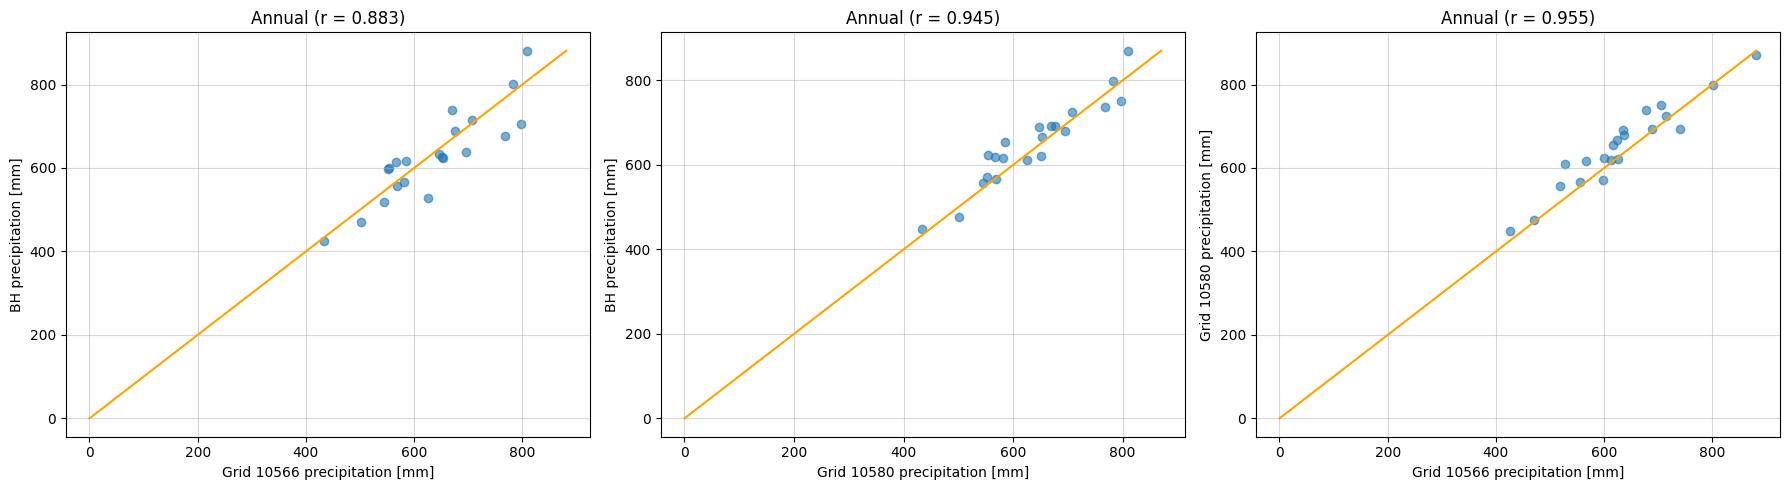

In [13]:
scatter_correlation_plots(griddf_sub, df_bh_sub, 'year') #yearly

The annual scatter plots show a generally strong linear relationship between the datasets, with correlation coefficients ranging from 0.883 to 0.955.

For BH and Gridcell 10566 (r = 0.883), the points show more scatter compared to the monthly scale, indicating weaker agreement. This may be influenced by the relatively small number of annual observations.

The comparison between BH and Gridcell 10580 (r = 0.945) shows a stronger linear relationship, with points more closely aligned to the 1:1 line, indicating better agreement.

For Gridcell 10566 and Gridcell 10580 (r = 0.955), the points are closely clustered along a linear trend, suggesting similar annual precipitation behaviour in the two grid cells.

Overall, the correlations remain high, but the scatter is more pronounced than at the monthly scale. This reflects the reduced number of data points at the annual scale, which makes the correlation more sensitive to variability between individual years.

### A.7.a

The standardized data for three reference periods from DMI is:

| Metric | 1961-1990 | 1981-2010 | 2006-2015 |
| :--- | :---: | :---: | :---: |
| Mean average precipitation [mm] | 712 | 746.2 | 791.9 |
| Days > 0.1 mm | 171 | 174.1 | 200.0 |
| Days > 10.0 mm | 17 | 18.9 | 20.3 |

The three datasets were compared to the DMI reference periods using mean annual precipitation and the number of wet days.

The mean annual precipitation for all three series (≈630–651 mm) is lower than all DMI reference values (712–792 mm), suggesting that the study period (1990–2010) is overall drier than the standard reference periods. The number of days with precipitation > 0.1 mm (151–164 days) is also lower than the DMI values (171–200 days), further supporting that the datasets represent a relatively drier period. The number of heavy precipitation days (>10 mm) is slightly lower (≈13.6–15.0 days) compared to the DMI reference values (17–20 days).

Among the datasets, Gridcell 10580 shows slightly higher precipitation totals and more wet days than Gridcell 10566, while BH has the highest number of heavy precipitation days. However, the differences between the three datasets are relatively small compared to the differences from the DMI reference periods.

Overall, none of the datasets match a specific DMI reference period particularly well, but they all appear to represent conditions that are drier than the standard reference climates. In terms of reference period, the data is within the 1981-2010. In terms of precipitation the data shows averaged values below the standardized data from DMI. A possible explanation may be that the gridcells and Botanisk Have generally recieve less precipitation, than other geographical locations in Denmark.

In [14]:
#defines function for merging gridcells and Botanisk Have data
def merged_three_series(df_bh_sub, griddf_sub, timescale):

    if timescale == 'day':
        keys = ['year', 'month', 'day']
    elif timescale == 'month':
        keys = ['year', 'month']
    elif timescale == 'year':
        keys = ['year']
    else:
        raise ValueError("timescale must be 'day', 'month' or 'year'")

    BH = (
        df_bh_sub
        .groupby(keys)['elem_val']
        .sum()
        .reset_index()
        .rename(columns={'elem_val': 'BH'})
    )

    grid10566 = (
        griddf_sub.loc[griddf_sub['gridcelle'] == 10566]
        .groupby(keys)['10*10km_Observed_precipitation_(mm)']
        .sum()
        .reset_index()
        .rename(columns={'10*10km_Observed_precipitation_(mm)': 'Grid10566'})
    )

    grid10580 = (
        griddf_sub.loc[griddf_sub['gridcelle'] == 10580]
        .groupby(keys)['10*10km_Observed_precipitation_(mm)']
        .sum()
        .reset_index()
        .rename(columns={'10*10km_Observed_precipitation_(mm)': 'Grid10580'})
    )

    merged = (
        BH
        .merge(grid10566, on=keys)
        .merge(grid10580, on=keys)
    )

    return merged, keys
#merge by day, and by year
merged_day, _  = merged_three_series(df_bh_sub, griddf_sub, 'day')
merged_year, _ = merged_three_series(df_bh_sub, griddf_sub, 'year')

#merging and saving the mean of the yearly values from the grids and Botanisk Have
yearly_mean_BH = merged_year["BH"].mean()
yearly_mean_10566 = merged_year["Grid10566"].mean()
yearly_mean_10580 = merged_year["Grid10580"].mean()



In [15]:
#defines a function to show days pr year over certain thresholds
def mean_days_over_threshold_per_year(merged_day, column, threshold):

    per_year = (
        merged_day
        .groupby("year")[column]
        .apply(lambda x: (x > threshold).sum())
    )

    return per_year.mean()


#uses the function to make a dataframe with values over threshold, to match data from DMI
dmi_table = pd.DataFrame({
    "Botanical Garden": [
        yearly_mean_BH,
        mean_days_over_threshold_per_year(merged_day, "BH", 0.1),
        mean_days_over_threshold_per_year(merged_day, "BH", 10.0),
    ],
    "Grid10566": [
        yearly_mean_10566,
        mean_days_over_threshold_per_year(merged_day, "Grid10566", 0.1),
        mean_days_over_threshold_per_year(merged_day, "Grid10566", 10.0),
    ],
    "Grid10580": [
        yearly_mean_10580,
        mean_days_over_threshold_per_year(merged_day, "Grid10580", 0.1),
        mean_days_over_threshold_per_year(merged_day, "Grid10580", 10.0),
    ],
}, index=["Yearly mean [mm]", "Days > 0.1 mm", "Days > 10 mm"])

display(round(dmi_table, 1))


,Botanical Garden,Grid10566,Grid10580
Yearly mean [mm],636.7,629.6,650.9
Days > 0.1 mm,151.2,163.3,164.3
Days > 10 mm,15.0,13.6,14.8


### A.7.b

When constructing a hydrological structure, it is important to consider the principle of worst-case scenario, meaning that it should be built to handle extreme weather events.

For the design of a hydrological structure, the BH station data would generally be preferred. This is because it is based on direct observations rather than spatially averaged values, and therefore better captures local rainfall extremes.

The gridded datasets tend to smooth precipitation over larger areas, which can underestimate extreme events. This makes them less suitable for design purposes where accurate representation of high-intensity rainfall is important.

However, the station data may also contain local biases and may not be fully representative of a larger area. Therefore, in practice, a combination of datasets or additional validation would often be recommended.

Overall, the placement and purpose of the hydrological structure should be considered when choosing which series to use. If the structure needs to withstand extreme localized weather events the Botanisk Have dataset is preferred due to its ability to better capture local rainfall variability and extremes. However if the structure needs to hold a large volume of water a gridded dataset is preferred due to its larger catchment area.

## Part B

### B.1

We consider the time series in datasheet "eventseries.csv". Looking at time windows of 10, 60 and 120 minutes we calculate the greatest total rainfall [mm] and greatest rainfall intensity [mm/hr] for each interval windows.

For total rainfall (volume/depth) we expect the largest value to be from the largest window due to the increased time of precipitation included for rainfall events, leading to increase in total precipitation.

Regarding intensity [mm/hr] we expect the largest outliers, ie. greatest single values, to be observed in the smallest time window data. The fewer data points per interval means the time interval window is sensitive to single extreme outliers in the observations.

In [16]:
#redefines the dataframe to match the new dataframe, and convert date-values to datetime
df = pd.read_csv("Assignment2_PartB_data/eventseries.csv", sep=';', usecols=['time', 'intensity_mm_hr'])
df['Date'] = pd.to_datetime(df['time'], format='%Y-%m-%d %H:%M:%S')

In [17]:
df = df.set_index('Date')

# Average intensity for each block
df_10min  = df['intensity_mm_hr'].resample('10min').mean()
df_60min  = df['intensity_mm_hr'].resample('60min').mean()
df_120min = df['intensity_mm_hr'].resample('120min').mean()

# Total rainfall (mm) for each block
per_minute_mm = df['intensity_mm_hr'] / 60

rain_10min  = per_minute_mm.resample('10min').sum()
rain_60min  = per_minute_mm.resample('60min').sum()
rain_120min = per_minute_mm.resample('120min').sum()

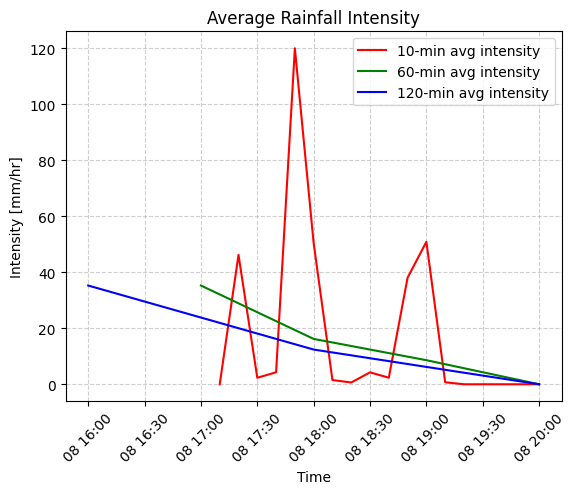

In [18]:
#plots average rainfall intensity for different time intervals
plt.plot(df_10min, label='10-min avg intensity', linewidth=1.5, color='red')
plt.plot(df_60min, label='60-min avg intensity', linewidth=1.5, color='green')
plt.plot(df_120min, label='120-min avg intensity', linewidth=1.5, color='blue')
plt.title('Average Rainfall Intensity')
plt.xlabel('Time')
plt.ylabel('Intensity [mm/hr]')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

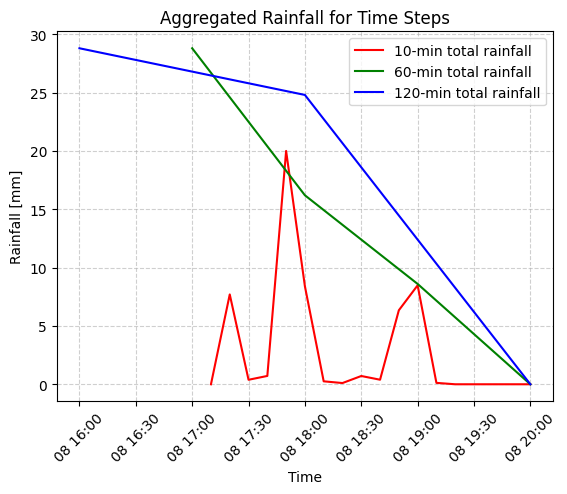

In [19]:
#plots aggregated rainfall intensity for different time intervals
plt.plot(rain_10min, label='10-min total rainfall', linewidth=1.5, color='red')
plt.plot(rain_60min, label='60-min total rainfall', linewidth=1.5, color='green')
plt.plot(rain_120min, label='120-min total rainfall', linewidth=1.5, color='blue')
plt.title('Aggregated Rainfall for Time Steps')
plt.xlabel('Time')
plt.ylabel('Rainfall [mm]')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [20]:
results = pd.DataFrame(
    [
        [df_10min.max(), rain_10min.max()],
        [df_60min.max(), rain_60min.max()],
        [df_120min.max(), rain_120min.max()]
    ],
    columns=["Greatest Intensity [mm/hr]", "Greatest Rainfall [mm]"],      # column names
    index=["10 min", "60 min", "120 min"]  # row names
).round(2)

display(results)

,Greatest Intensity [mm/hr],Greatest Rainfall [mm]
10 min,120.00,20.0
60 min,35.27,28.8
120 min,35.27,28.8


### B.2

We now consider the data from "rainevents.csv" with 7200 rain events recorded over a 37 year timeline. From this data we create two Partial Duration Series (PDS), for the rainfall intensities [mm/hr] in the intervals 10 and 60 minutes. 

The PDS containing the n largest events are of a type two samling method. Meaning the threshold is the random variable. We set the threshold of our PDS based on our timeline period $t_{obs} = 37$ and rate per year $\lambda = 2$ to get $n = t_{obs} \lambda = 37 \cdot 2 = 74$.

From this we rank our intensity values from highest to lowest. Knowing our PDS must include the 74th greatest events, and our threshold as the exact 74th greatest intensity event. 

This gives us the threshold intensities for 10-minute interval at $\textbf{32.40 mm/hr}$ and for 60-minute interval at $\textbf{7.65 mm/hr}$.

Below is a plot showing events over time with the threshold line applied for each of the two intervals.

In [21]:
#defines dataframe for rainevents
df_rainevents = pd.read_csv("Assignment2_PartB_data/rainevents.csv", sep=';', usecols=['start','end','TotalRainfall_mm','Intensity_10min_mm_hr','Intensity_60min_mm_hr','Intensity_120min_mm_hr','Duration_min'])
df_rainevents['start'] = pd.to_datetime(df_rainevents['start'], format='%Y-%m-%d %H:%M:%S')
df_rainevents['end'] = pd.to_datetime(df_rainevents['end'], format='%Y-%m-%d %H:%M:%S')

In [22]:
#We need to define n. Knowing that we should choose the on average 2 largest events per year. We are informed, that the data covers a periode of 37 years. Therefore n is defined as: 
n = 2*37 #rate * t_obs

## 10 min data
#sort df_rainevents by column; "Intensity_10min_mm/hr" in descending order and reset index.  
rank_10_sorted = df_rainevents.sort_values(by='Intensity_10min_mm_hr', ascending=False).reset_index()

#Saving the 74 highest values
rank_10 = rank_10_sorted[0:n] 
rank_10_threshold = rank_10['Intensity_10min_mm_hr'][n-1]

#Sorts after date
df_rank_10 = rank_10.sort_values(by='start', ascending=True).reset_index()

## 60 min data
#sort df_rainevents by column; "Intensity_60min_mm/hr" in descending order and reset index.  
rank_60_sorted = df_rainevents.sort_values(by='Intensity_60min_mm_hr', ascending=False).reset_index()

#Saving the 74 highest values
rank_60 = rank_60_sorted[0:n]
rank_60_threshold = rank_60['Intensity_60min_mm_hr'][n-1]

#Sorts after date
df_rank_60 = rank_60.sort_values(by='start', ascending=True).reset_index()


In [23]:
#plot spikes for all events, and marking points above thresholdline with dots
def plot_pds_spikes(df_all, df_top, column, threshold, n, title=None):
    df_all = df_all.sort_values("start").reset_index(drop=True)
    df_top = df_top.sort_values("start").reset_index(drop=True)

    plt.figure(figsize=(20, 8))

    # Spikes for all events
    plt.vlines(df_all["start"], 0, df_all[column], label="All events")

    # Dots for top-n events
    plt.scatter(df_top["start"][:n], df_top[column][:n],
                s=40, marker="o", color="orange", label=f"Top {n} events", zorder=3)

    # Threshold line
    plt.axhline(threshold, color="red", linestyle="--",
                label=f"Threshold (rank {n}) = {threshold:.2f} [mm/hr]")

    plt.xlabel("Time")
    plt.ylabel(column)
    plt.title(title if title else f"PDS (2 events/year): {column}")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"Threshold Intensity for {column}: {threshold:.2f} [mm/hr]")


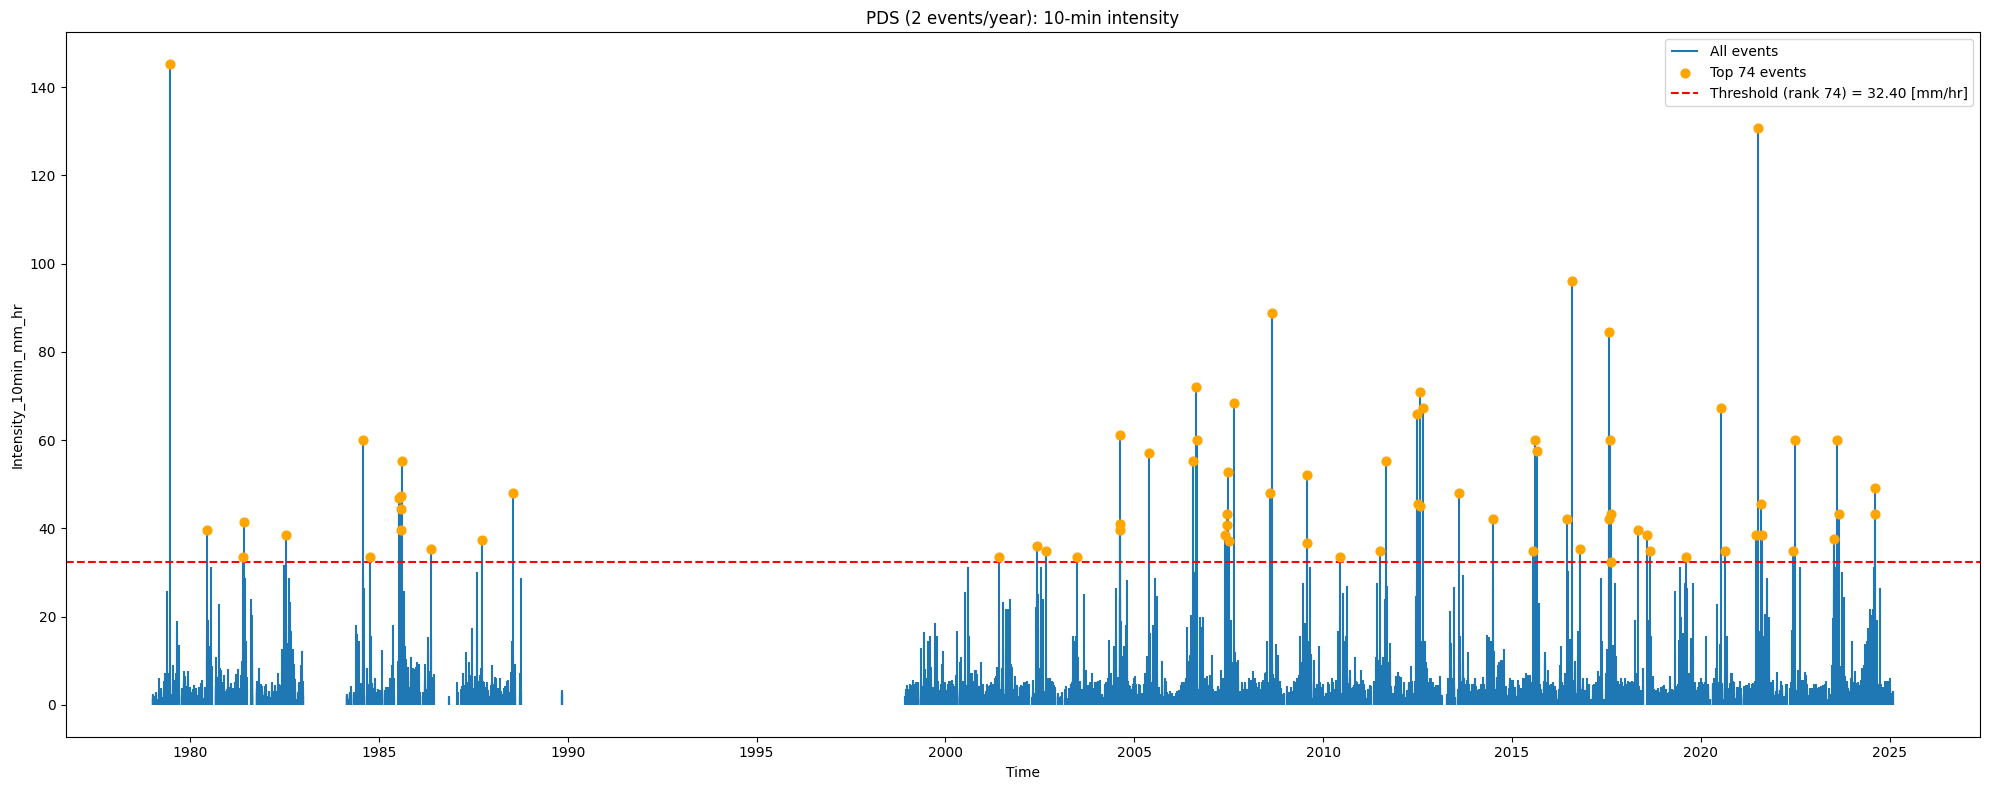

Threshold Intensity for Intensity_10min_mm_hr: 32.40 [mm/hr]


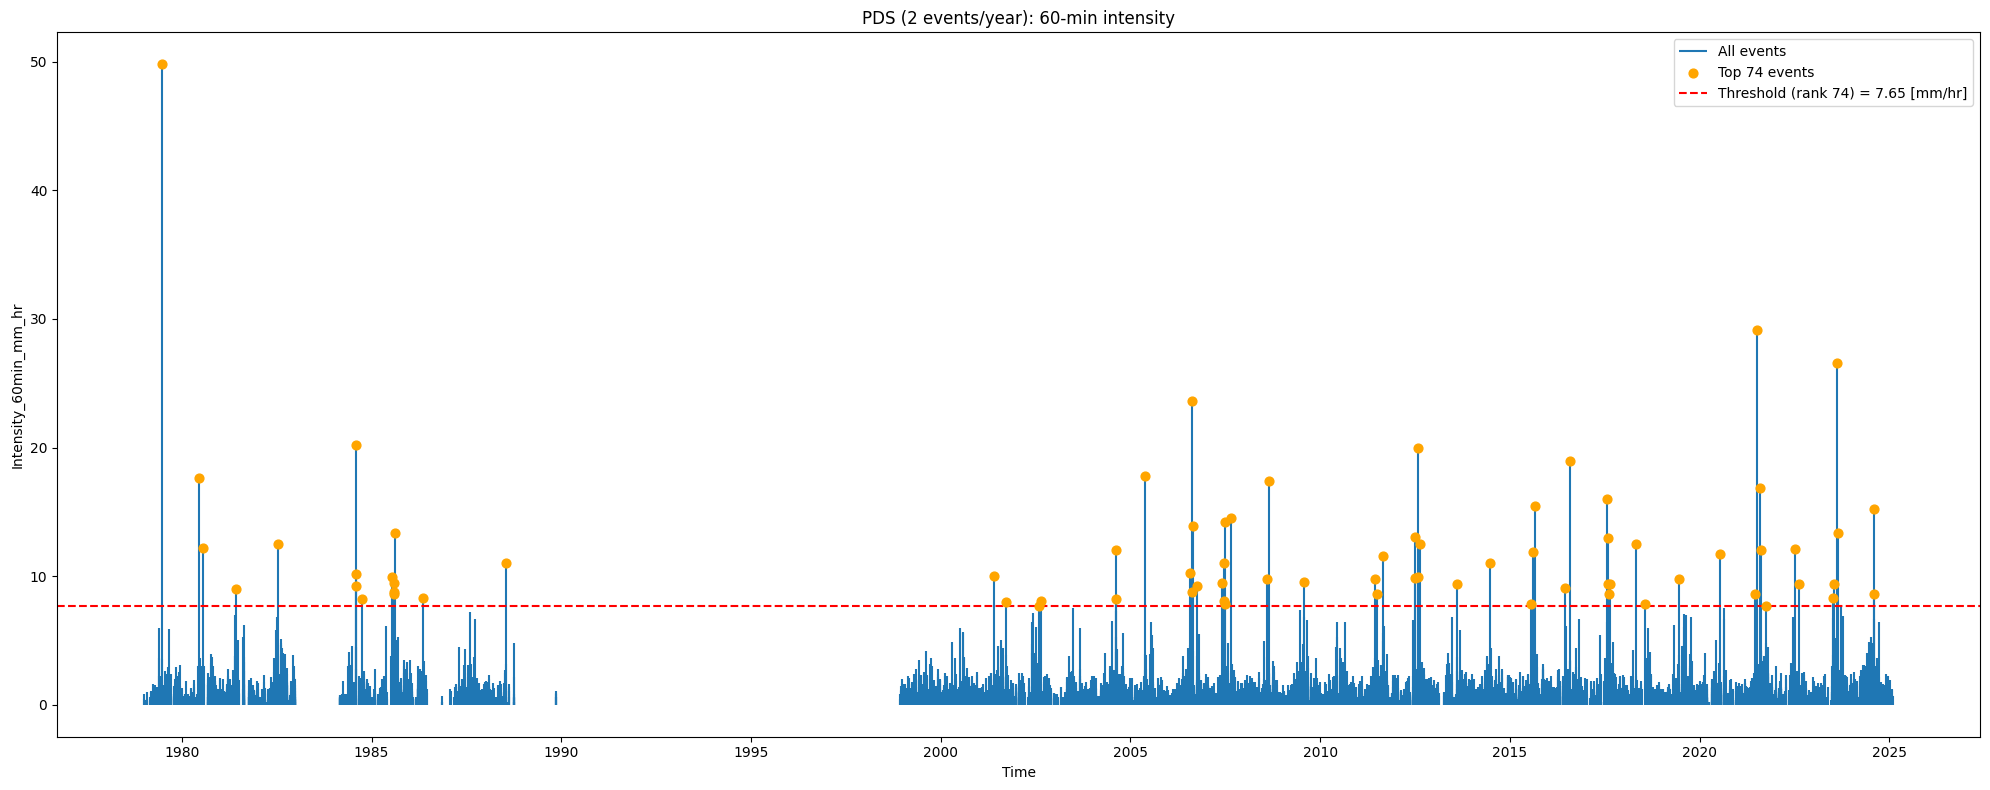

Threshold Intensity for Intensity_60min_mm_hr: 7.65 [mm/hr]


In [24]:
#uses the function to plot graphs for 60 min intensity and 60 min intensity
plot_pds_spikes(df_rainevents, df_rank_10, "Intensity_10min_mm_hr", rank_10_threshold, n,
                title="PDS (2 events/year): 10-min intensity")

plot_pds_spikes(df_rainevents, df_rank_60, "Intensity_60min_mm_hr", rank_60_threshold, n,
                title="PDS (2 events/year): 60-min intensity")

### B.3

In order to apply statistical models/test on a data set, it is important first to check for independence of the observations and also the stationarity. The data must be stationary to ensure that the dataset only differs due to random variation. 

This can be done by applying a Wald-Wolfowitz Runs test on the definede extreme values extracted from the dataset.
The following test statitistc are used: 

$$\mu = \frac{2N_+ \cdot N_-}{N}+1$$

$$\sigma^2 = \frac{(\mu-1)(\mu-2)}{N-1}$$

$$T = \frac{R-\mu}{\sigma}$$

We define a variabel for an $R$-counter which increases each time a consequative series of events crosses our median value. We also setup and $N_-$ and $N_+$ counter to see how many of our events are above and below our median. 

Values precisely at the median value have been excluded under the assumption that they will not skew our observations and will have equal impact on both $N_-$ and $N_+$.

It should be noted that R also increases when hitting the precise median value, again due to an assumption that this will happen equally for series of events above and below the median line

In [25]:
# Formating of the dataframes, for the WW-Run test.

#remove timeseries in data, that has a large data gap. 
mask = ((df_rainevents['start'] >= '1988-10-01') &
        (df_rainevents['start'] <= '1998-12-31'))

#define new data_frame, and reset index
df_rank_10 = df_rank_10[df_rank_10['index'].isin(df_rainevents[~mask].reset_index()['index'])]
df_rank_60 = df_rank_60[df_rank_60['index'].isin(df_rainevents[~mask].reset_index()['index'])]

#calculate time differences between start and end values of each rainfall event with 10 min intensities. 
df_rank_10['Time_between'] = df_rank_10['start'] - df_rank_10['end'].shift(1)
df_rank_10.loc[df_rank_10['Time_between'] > pd.Timedelta(days=365*10),'Time_between'] = pd.NaT

#calculate time differences between start and end values of each rainfall event with 60 min intensities. 
df_rank_60['Time_between'] = df_rank_60['start'] - df_rank_60['end'].shift(1)
df_rank_60.loc[df_rank_60['Time_between'] > pd.Timedelta(days=365*10),'Time_between'] = pd.NaT



Redegør for præcis median værdi. 

In [26]:
#defines function to run precipication intensity events, and determine number of uninterrupted sequences of rainevents,
def WW_Run_Test(df,column, alpha):
    median = df[column].median()
    print(f'Median: {median}')
    R= 0
    for i in range(len(df)-1):
        if df[column][i] < median and df[column][i+1] > median:
            R += 1

        elif df[column][i] > median and df[column][i+1] < median:
            R += 1

        elif df[column][i] == median:
            R += 1  
            
        else: 
            continue
   
    print(f'Number of uninterrupted sequences of the same class, R: {R}')
    
    N_minus = 0
    N_plus= 0
    
    for i in range(len(df)):
        if df[column][i] < median:
            N_minus += 1
        elif df[column][i] > median:
            N_plus += 1
    print(f'N_plus is: {N_plus}, N_minus is: {N_minus}')
    
    N = len(df)
    mu = (2*N_plus*N_minus)/N + 1
    print(f'mu is: {mu:.2f}')
    
    sigma = ((mu-1)*(mu-2)) / (N-1)
    print(f'sigma is: {sigma:.3f}')
    
    T = (R - mu) / np.sqrt(sigma)
    print(f'The test statistic T: {T:.2f}')

    #calculating pvalue, and determine whether nul-hypothesis can be rejected
    pvalue = 2*(1-stats.t.cdf(abs(T),df=N-1))
    print(f'The p-values is: {pvalue:.2f}')
    if pvalue < alpha:
        print(f'The nul-hypothesis is rejected using an {(1-alpha)*100}% confidence interval, meaning the data is not i.i.d')
    else:
        print(f'The nul-hypothesis is not rejected using an {(1-alpha)*100}% confidence interval, meaning the data is i.i.d')
        print('We can assume, that our data is stationary')    
              
    return R, N_plus, N_minus, mu, sigma, T, pvalue

In [27]:
R_tr_10, N_plus_tr_10, N_minus_tr_10, mu_tr_10, sigma_tr_10, T_tr_10, p_tr_10 = WW_Run_Test(df_rank_10,'Intensity_10min_mm_hr',0.05)

Median: 43.2
Number of uninterrupted sequences of the same class, R: 37
N_plus is: 35, N_minus is: 36
mu is: 35.05
sigma is: 15.420
The test statistic T: 0.50
The p-values is: 0.62
The nul-hypothesis is not rejected using an 95.0% confidence interval, meaning the data is i.i.d
We can assume, that our data is stationary


In [28]:
R_tr_60, N_plus_tr_60, N_minus_tr_60, mu_tr_60, sigma_tr_60, T_tr_60 , p_tr_60 = WW_Run_Test(df_rank_60,'Intensity_60min_mm_hr',0.05)

Median: 9.979949999999999
Number of uninterrupted sequences of the same class, R: 42
N_plus is: 37, N_minus is: 37
mu is: 38.00
sigma is: 18.247
The test statistic T: 0.94
The p-values is: 0.35
The nul-hypothesis is not rejected using an 95.0% confidence interval, meaning the data is i.i.d
We can assume, that our data is stationary


In [29]:
R_tb_10, N_plus_tb_10, N_minus_tb_10, mu_tb_10, sigma_tb_10, T_tb_10, p_tb_10 = WW_Run_Test(df_rank_10,'Time_between',0.05)

Median: 54 days 06:56:00
Number of uninterrupted sequences of the same class, R: 33
N_plus is: 36, N_minus is: 36
mu is: 36.03
sigma is: 16.327
The test statistic T: -0.75
The p-values is: 0.46
The nul-hypothesis is not rejected using an 95.0% confidence interval, meaning the data is i.i.d
We can assume, that our data is stationary


In [30]:
R_tb_60, N_plus_tb_60, N_minus_tb_60, mu_tb_60, sigma_tb_60, T_tb_60, p_tb_60 = WW_Run_Test(df_rank_60,'Time_between',0.05)

Median: 39 days 21:03:00
Number of uninterrupted sequences of the same class, R: 29
N_plus is: 36, N_minus is: 36
mu is: 36.03
sigma is: 16.327
The test statistic T: -1.74
The p-values is: 0.09
The nul-hypothesis is not rejected using an 95.0% confidence interval, meaning the data is i.i.d
We can assume, that our data is stationary


Based on the WW-run test all our dataseries are determined to be i.i.d and stationary, meaning we can now perform statistical models on our data knowing that the variation is not systematic, but only due to randomnes in the data.

### B.4

We determine an empirical estimate of return periods of the events in the PDS using the median plotting position as the estimate of exceedance probability.

We define a new dataframe only including the top 74 values of our observations. Then the median plotting position equation is computed for 74 events.

A semi-logarithmic regression is conducted with our estimated return period $T_P$ as the slope and the intensity data from our dataset as the intercept.

The intensity is plotted with logarithmic x-axis making the plot semilogarithmic to show a linear regression fit of our intensities over return period.

In [31]:

PDS_10 = rank_10[0:n]
PDS_60 = rank_60[0:n]

i = np.arange(1, n+1)

#exceedance probabilities using the median rank method
pi_med = (i - 0.3) / (n + 0.4)

#Return periods
Tp = np.array([1/pi for pi in pi_med])

In [32]:

def empirical_regression(pds, intensity_int):
    res = np.polyfit(np.log10(Tp), pds[str(intensity_int)], 1) #prints (slope, intercept)
    print(res)

    plt.plot(Tp, pds[str(intensity_int)], marker='o', linestyle='none', label='Median', color='red')
    x_plot = np.linspace(1,150,200)
    plt.plot(x_plot, res[0]*np.log10(x_plot) + res[1], color='grey', label='Median')
    plt.ylabel(f"Intensity {str(intensity_int)[10:12]} min [mm/hr]")
    plt.xlabel('Return Period')
    plt.xscale('log')
    plt.title(f"Intensity {str(intensity_int)[10:12]} min [mm/hr] for PDS Events")
    plt.show()

[47.81147692 29.57996804]


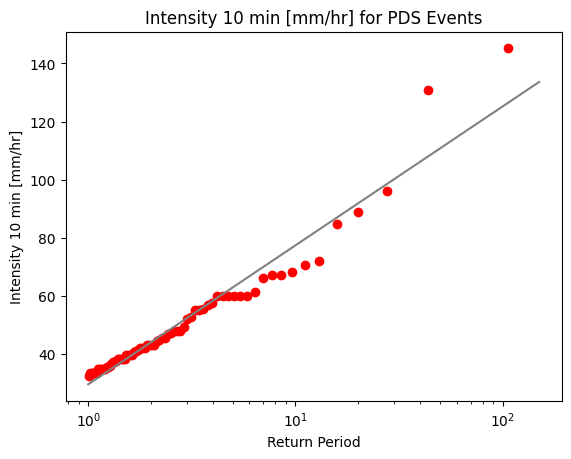

[14.21222441  6.24753921]


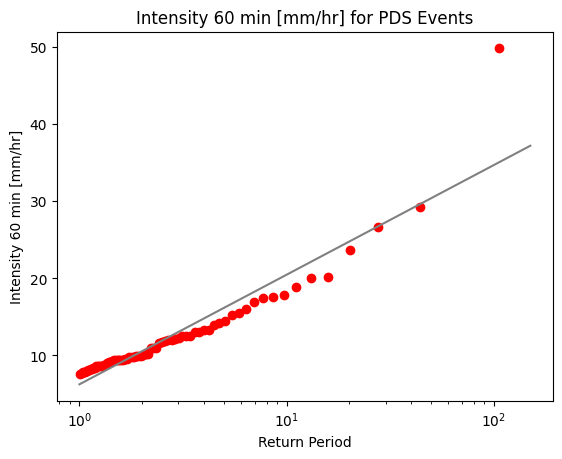

In [33]:
empirical_regression(PDS_10, 'Intensity_10min_mm_hr')
empirical_regression(PDS_60, 'Intensity_60min_mm_hr')

As seen in the plots there is a strong correlation between our median semilogarithmic regression and the median plotting positioned observations. It should however be noted that the upmost extreme values highly deviate from the trendline. 

As return period increases so does the uncertainty in correlation to our regression line for our empirical data.

### B.5

Plot CDF against empirically derived values. Parameters for moment estimates are found assuming GPD distribution with estimated threshold intensity for location ($\xi$).

$$ \xi = \text{Threshold Intensity of Interval} $$

$$ \hat{\mu} = \frac{1}{n} \sum_{i=1}^{n} x_i $$

$$ \hat{\sigma} = \sqrt{\frac{1}{n-1} \sum_{i=1}^{n} (x_i - \bar{x})^2} $$

$$\hat{k} = \frac{1}{2} \left[ \left( \frac{\hat{\mu} - \xi}{\hat{\sigma}} \right)^2 - 1 \right]$$

$$ \hat{\alpha} = (\hat{\mu} - \xi)(1 + \hat{\kappa}) $$
<br>
With our parameters found, we may insert into our CDF:

$$ \mathrm{CDF} = 1 - \left( 1 - \kappa \frac{(x - \xi)}{\alpha} \right)^{1/\kappa}, \quad where \; \xi \leq x<\infty $$
<br>
This plot gives us the probabilities of observed intensities when a rain event occurs.

To plot rain intensities as a function of return periods for the fitted model, $x_T$ is calculated for a linspace of return periods ($T$).

$$ x_T = \xi + \frac{\alpha}{\kappa}\left[1 - \frac{1}{T}^{\kappa}\right] $$

This plot gives us the return periods of observed intensities.

In [34]:
def cdf_empirical(pds, intensity_int):
    xi = pds[str(intensity_int)].min() #location fixed to threshold intensity from Q2
    mu = pds[str(intensity_int)].mean()
    sigma = pds[str(intensity_int)].std()
    kappa = 0.5 * (((mu-xi)/sigma)**2 - 1)
    alpha = (mu - xi)*(1 + kappa)
    print(f"The shape parameter kappa is: {round(kappa,2)}")

    x = np.linspace(xi, pds[str(intensity_int)][0], 200)
    CDF = 1 - (1 - kappa*(x-xi)/alpha)**(1/kappa)

    T_plot = np.linspace(1.5,80,200)
    xT = xi + (alpha/kappa)*(1 - (1/T_plot)**kappa)

    # Plot
    fig, ax = plt.subplots(1, 2, figsize=(12,4))

    fig.suptitle(f"Intensity {str(intensity_int)[10:12]} min [mm/hr]", fontweight='bold')

    # Left: CDF
    ax[0].plot(x, CDF, color='black', label='CDF')
    ax[0].plot(pds[str(intensity_int)], 1 - pi_med, marker='o', color='darkblue', label='Median', linestyle='none')
    ax[0].set_ylabel('CDF')
    ax[0].set_xlabel(str(intensity_int))
    ax[0].legend()
    ax[0].grid(True, alpha=0.3)

    # Right: Return level
    ax[1].plot(T_plot, xT, linestyle='-', label='xT', color='black', alpha=0.8)
    ax[1].plot(Tp/2, pds[str(intensity_int)], linestyle='none', label='Observations', marker='o', color='darkblue')
    ax[1].set_xlabel('Return Period [years]')
    ax[1].set_ylabel('Intensity [mm/hr]')
    ax[1].legend()
    ax[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
    

The shape parameter kappa is: -0.12


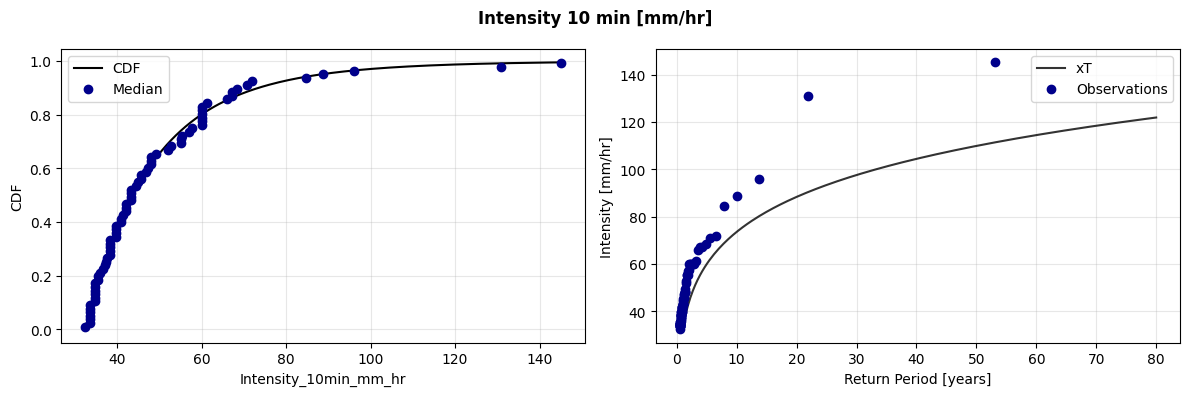

The shape parameter kappa is: -0.22


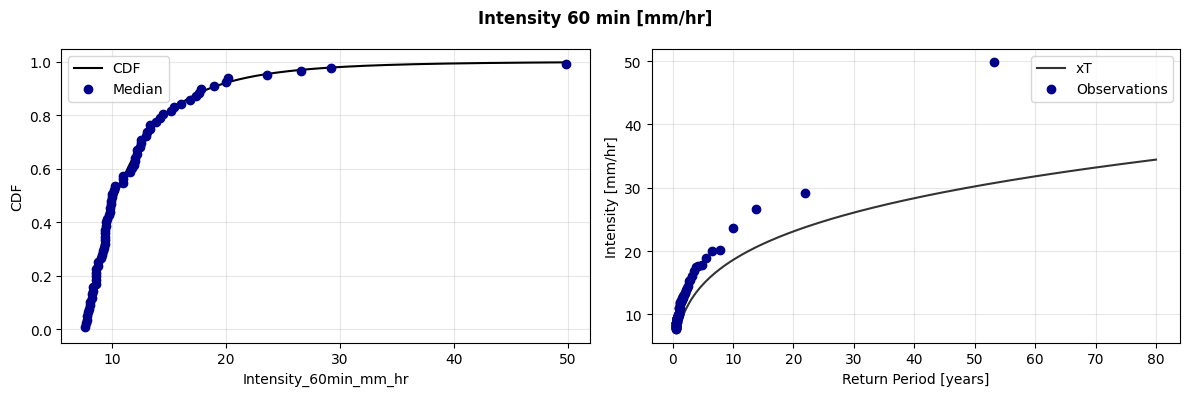

In [35]:
cdf_empirical(PDS_10, 'Intensity_10min_mm_hr')
cdf_empirical(PDS_60, 'Intensity_60min_mm_hr')

In our plots we see a good fit between empirical data and CDF for GPD distribution, with a slightly better fit for 60-minutes as it shows less volatility.

However, plotting intensity over return period for our fitted model using the $x_T$ equation, we see a an underestimation in intensity across all return periods. The greater the return period the greater the underestimation.

This highlights an uncertainty in moments parameters in regards to the principle of safety, when predicting extreme events. This should be taken into account if used for risk assessment of projects invovling extreme events.

### B.6

In an annual maximum series (AMS) the biggest event each year is extracted. 

A generalized extreme value (GEV) distribution takes three parameters ($\xi$: location, $\alpha$: scale, $\kappa$:shape). If the scale parameter is equal to zero, the GEV distribution is simplified to a gumble distribution, which only $\xi$ takes and $\alpha$ as input parameters. Based on the previous step (QB5), the scale parameter for both rainfall event series was determined to be different from zero, indicating, that a GEV distribution would be a better fit, and should be preformed.

The GEV and GPD describes the same tail but through two different sampling mechanisms. Where the GEV describes the distrubution through maxima. 


First a new dataset is constructed, where the largest rainfall event each year is extracted to create the AMS series. 

In [36]:
#data, that has a large data gap. 
mask = ((df_rainevents['start'] >= '1988-10-01') &
        (df_rainevents['start'] <= '1998-12-31'))

#define new data_frame, and reset index
rank_10_sorted = df_rainevents[~mask].reset_index()
rank_10_sorted['year'] = rank_10_sorted['start'].dt.year
df_rank_10_AMS = rank_10_sorted.groupby('year').max()
df_rank_10_AMS = df_rank_10_AMS.sort_values(by='Intensity_10min_mm_hr', ascending=False)

rank_60_sorted = df_rainevents[~mask].reset_index()
rank_60_sorted['year'] = rank_60_sorted['start'].dt.year
df_rank_60_AMS = rank_60_sorted.groupby('year').max()
df_rank_60_AMS = df_rank_60_AMS.sort_values(by='Intensity_60min_mm_hr', ascending=False)


The parameters of the GEV a Gumbel distribution are calculated using the lmoments3 package. 
Comparing the loc and scale parameters between the GEV and gumble distributions it is noticed, that the parameters are bigger for the gumble than the GEV, and it is checked that the kappa for the GEV is not zero, as inticipated from Q.B5.

In [37]:
import lmoments3 as lm
from lmoments3 import distr

#gev = lm.dtir.gev
gev_params_10 = distr.gev.lmom_fit(df_rank_10_AMS['Intensity_10min_mm_hr'])
gum_params_10 = distr.gum.lmom_fit(df_rank_10_AMS['Intensity_10min_mm_hr'])

gev_params_60 = distr.gev.lmom_fit(df_rank_60_AMS['Intensity_60min_mm_hr'])
gum_params_60 = distr.gum.lmom_fit(df_rank_60_AMS['Intensity_60min_mm_hr'])

print(f"The parameters of the GEV distribution for rainfall events of 10 min intensities are:")
print(f"loc: {gev_params_10['loc']:.2f}, scale: {gev_params_10['scale']:.2f}, kappa: {gev_params_10['c']:.2f}")

print(f"The parameters of the Gumbel distribution for rainfall events of 10 min intensities are:")
print(f"loc: {gum_params_10['loc']:.2f}, scale: {gum_params_10['scale']:.2f}")

print(f"The parameters of the GEV distribution for rainfall events of 60 min intensities are:")
print(f"loc: {gev_params_60['loc']:.2f}, scale: {gev_params_60['scale']:.2f}, kappa: {gev_params_60['c']:.2f}")

print(f"The parameters of the Gumbel distribution for rainfall events of 60 min intensities are:")
print(f"loc: {gum_params_60['loc']:.2f}, scale: {gum_params_60['scale']:.2f}")

The parameters of the GEV distribution for rainfall events of 10 min intensities are:
loc: 42.24, scale: 18.60, kappa: -0.11
The parameters of the Gumbel distribution for rainfall events of 10 min intensities are:
loc: 43.23, scale: 20.86
The parameters of the GEV distribution for rainfall events of 60 min intensities are:
loc: 10.14, scale: 5.05, kappa: -0.17
The parameters of the Gumbel distribution for rainfall events of 60 min intensities are:
loc: 10.57, scale: 6.10


In [38]:
from scipy.stats import genextreme, gumbel_r

def plot_AMS(params, empirical_data, intensity_int):
    # Define params
    c = params['c']
    loc = params['loc']
    scale = params['scale']

    # defining n, i and the median excedance plotting possition. 
    n_AMS = len(empirical_data[intensity_int])
    i_AMS = np.arange(1, n_AMS+1)
    pi_med_AMS = (i_AMS - 0.3) / (n_AMS + 0.4)
    Tp_AMS = np.array([1/pi for pi in pi_med_AMS])
    
    # Define the lenght of x-axis on the cdf plot:
    maks = empirical_data[intensity_int].max()
    print(maks)
    x = np.linspace(0,maks+5,n_AMS)

    # Define the cdf for the genereal extreme value distribution.
    func = genextreme.cdf(x,c,loc,scale)
    
    # Define 
    T = sp.symbols('T')
    expr = loc + scale / c *(1-(-sp.log(1-1/T))**c)
    T_max = sp.nsolve(sp.Eq(maks,expr),10)
    print(T_max)
    T_plot = np.linspace(1.5,float(T_max)+5,200)
    xT = loc + scale / c *(1-(-np.log(1-1/T_plot))**c)
    
    # ---------- Plot ----------
    fig, ax = plt.subplots(1, 2, figsize=(8,4))

    fig.suptitle(f"Intensity {str(intensity_int)[10:12]} min (mm/hr)", fontweight='bold')

    # Left: CDF
    ax[0].plot(x, func, color='black', label='GEV Distribution')
    ax[0].plot(empirical_data[intensity_int],1-pi_med_AMS, marker='o', linestyle='none', label='AMS empirical data', color='red')
    ax[0].set_ylabel('CDF')
    ax[0].set_xlabel('Intensity [mm/hr]')
    ax[0].grid(True, alpha=0.3)
    ax[0].legend()
    ax[0].set_title('CDF of Intensity')

    # Right: Return level

    ax[1].plot(T_plot, xT, linestyle='-', label='Fitted model', color='black', alpha=0.8)
    ax[1].plot(Tp_AMS, empirical_data[intensity_int], linestyle='none', label='AMS empirical data', marker='o', color='darkblue')
    ax[1].set_xlabel('Return Period [year]')
    ax[1].set_ylabel('Intensity mm/hr')
    ax[1].grid(True, alpha=0.3)
    ax[1].legend()
    ax[1].set_title('Return period')
    
    plt.tight_layout()
    plt.show()

145.19952
74.7769776378855


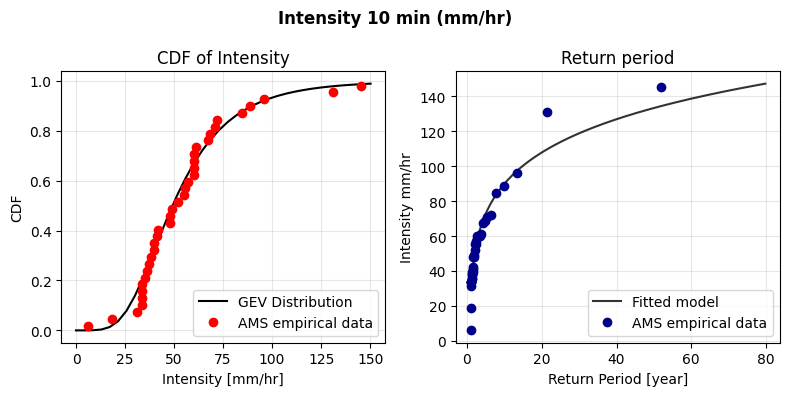

In [39]:
plot_AMS(gev_params_10,df_rank_10_AMS,'Intensity_10min_mm_hr')

49.79994
140.724280267404


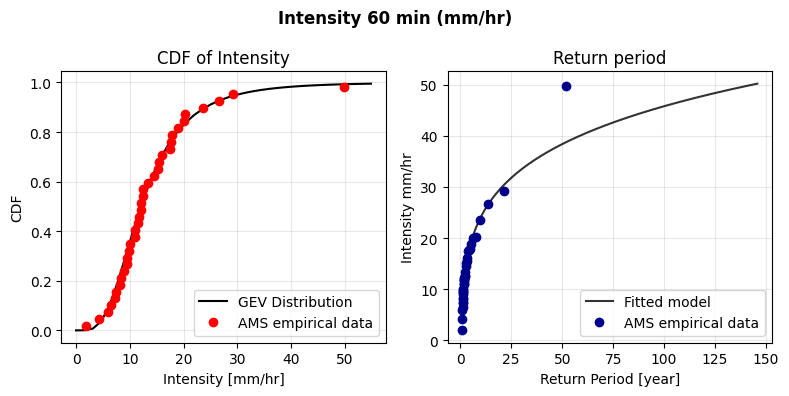

In [40]:
plot_AMS(gev_params_60,df_rank_60_AMS,'Intensity_60min_mm_hr')

In our plots we see a good fit between empirical data and CDF for GEV distribution, with a slightly better fit for 60-minutes as it shows less volatility.

Comparing our plots in Q.B6 with the plots in Q.B5 the fitted model for the return period is better fitting, due to a lesser amount of datapoints in the low end of the intensity scale. This means, that the underestimation of return periods is less. 

## *Declaration of AI*

This notebook has been developed for assignment 2 in the course 12320 Hydrology F26 at DTU Lyngby.

This assingment has been produced with the use of ChatGPT model 5.2 during February of 2026.

The AI has been used to help with data infrastructure setup, syntax errors and generel coding assistance.

All contents of this notebook have been read, reviewed and edited to ensure it represents the understanding of the students of admission and fulfills assignment requirements. 

The students of admission takes full responsibility for the contents of this notebook.